# Analyze abundant 25x20: none vs Gini

In [2]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 260)

def find_repo_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "opinion_dynamics").exists():
            return candidate
    raise RuntimeError("Could not find repository root.")

REPO_ROOT = find_repo_root()
RESULTS_ROOT = REPO_ROOT / "opinion_dynamics" / "experiments" / "results"
RESULTS_DIR = RESULTS_ROOT / "experiment_2026_10_02_abundant_matched_distribution_25x20_none_vs_gini"
OUT = RESULTS_ROOT / "analysis_2026_10_02_abundant_25x20_none_vs_gini"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RESULTS_DIR / "combined_summary.csv")
learned = df[df["regularizer_kind"].isin(["none", "gini"])].copy()

print("Rows:", len(df))
print("Learned rows:", len(learned))
print(learned.groupby(["regularizer_kind", "learning_seed"]).size().to_string())


Rows: 1755
Learned rows: 1170
regularizer_kind  learning_seed
gini              0.0              195
                  1.0              195
                  2.0              195
none              0.0              195
                  1.0              195
                  2.0              195


In [3]:

KEY = [
    "environment_id", "environment_index", "scenario_class",
    "family", "dynamics", "learning_seed"
]
METRICS = [
    "mean_end", "model_over_identity", "row_TV", "A_MAE",
    "true_edge_mass", "edge_AP", "centrality_L1",
    "row_entropy_norm", "effective_neighbors"
]

p = learned.pivot_table(
    index=KEY,
    columns="regularizer_kind",
    values=METRICS,
    aggfunc="first",
)
p.columns = [f"{m}__{k}" for m, k in p.columns]
p = p.reset_index()

for m in METRICS:
    p[f"delta_{m}"] = p[f"{m}__gini"] - p[f"{m}__none"]

p.to_csv(OUT / "paired_environment_seed.csv", index=False)

overall = pd.DataFrame({
    "metric": METRICS,
    "none": [p[f"{m}__none"].mean() for m in METRICS],
    "gini": [p[f"{m}__gini"].mean() for m in METRICS],
    "gini_minus_none": [p[f"delta_{m}"].mean() for m in METRICS],
})
overall.to_csv(OUT / "overall_comparison.csv", index=False)
display(overall.round(6))


,metric,none,gini,gini_minus_none
0,mean_end,0.754189,0.750576,-0.003613
1,model_over_identity,0.702866,0.697941,-0.004924
2,row_TV,0.620230,0.611772,-0.008458
3,A_MAE,0.082697,0.081570,-0.001128
4,true_edge_mass,0.395216,0.411360,0.016143
5,edge_AP,0.676612,0.634575,-0.042037
6,centrality_L1,0.520156,0.512584,-0.007572
7,row_entropy_norm,0.918372,0.890924,-0.027448
8,effective_neighbors,11.414554,10.635043,-0.779511


In [4]:

by_dyn = (
    p.groupby(["scenario_class", "dynamics"], as_index=False)
    .agg(
        n=("environment_id", "size"),
        none_control=("mean_end__none", "mean"),
        gini_control=("mean_end__gini", "mean"),
        delta_control=("delta_mean_end", "mean"),
        none_rowTV=("row_TV__none", "mean"),
        gini_rowTV=("row_TV__gini", "mean"),
        delta_rowTV=("delta_row_TV", "mean"),
        none_edge_AP=("edge_AP__none", "mean"),
        gini_edge_AP=("edge_AP__gini", "mean"),
        delta_edge_AP=("delta_edge_AP", "mean"),
        none_pred_ratio=("model_over_identity__none", "mean"),
        gini_pred_ratio=("model_over_identity__gini", "mean"),
        delta_pred_ratio=("delta_model_over_identity", "mean"),
    )
)
by_dyn.to_csv(OUT / "comparison_by_dynamics.csv", index=False)
display(by_dyn.round(6))


,scenario_class,dynamics,n,none_control,gini_control,delta_control,none_rowTV,gini_rowTV,delta_rowTV,none_edge_AP,gini_edge_AP,delta_edge_AP,none_pred_ratio,gini_pred_ratio,delta_pred_ratio
0,structured_mechanism,friedkinjohnsen,45,0.613675,0.613675,0.000000,0.392133,0.389719,-0.002414,0.792129,0.789454,-0.002674,0.297100,0.294356,-0.002744
1,structured_mechanism,hegselmannkrause,45,0.631259,0.622440,-0.008819,0.726575,0.725977,-0.000598,0.550455,0.535402,-0.015053,1.084085,1.081566,-0.002519
2,structured_mechanism,nonlinearinfluence,45,0.865175,0.865180,0.000005,0.458770,0.453374,-0.005396,0.789035,0.750721,-0.038314,0.338770,0.332834,-0.005936
3,unstructured_random,coca,75,0.772884,0.770100,-0.002784,0.768293,0.764612,-0.003680,0.385956,0.308449,-0.077507,0.931886,0.929100,-0.002786
4,unstructured_random,friedkinjohnsen,75,0.683595,0.683695,0.000100,0.540975,0.538849,-0.002126,0.904602,0.902893,-0.001708,0.503067,0.501836,-0.001231
5,unstructured_random,hegselmannkrause,75,0.827698,0.824518,-0.003180,0.596711,0.584105,-0.012606,0.819162,0.781849,-0.037313,0.772773,0.765748,-0.007025
6,unstructured_random,laplacian,75,0.803878,0.791588,-0.012290,0.604335,0.583473,-0.020862,0.814678,0.664361,-0.150317,0.440485,0.434893,-0.005592
7,unstructured_random,nonlinearinfluence,75,0.829002,0.827114,-0.001888,0.574604,0.552635,-0.021969,0.860124,0.832809,-0.027315,0.465952,0.451971,-0.013981
8,unstructured_random,repulsion,75,0.699551,0.696699,-0.002853,0.806389,0.806703,0.000313,0.214084,0.213978,-0.000105,1.336217,1.335142,-0.001075


In [5]:

hk = p[
    (p["scenario_class"] == "structured_mechanism")
    & (p["dynamics"] == "hegselmannkrause")
].copy()

hk_family = (
    hk.groupby("family", as_index=False)
    .agg(
        n=("environment_id", "size"),
        none_control=("mean_end__none", "mean"),
        gini_control=("mean_end__gini", "mean"),
        delta_control=("delta_mean_end", "mean"),
        none_rowTV=("row_TV__none", "mean"),
        gini_rowTV=("row_TV__gini", "mean"),
        delta_rowTV=("delta_row_TV", "mean"),
        none_edge_AP=("edge_AP__none", "mean"),
        gini_edge_AP=("edge_AP__gini", "mean"),
        delta_edge_AP=("delta_edge_AP", "mean"),
    )
)
hk_family.to_csv(OUT / "structured_HK_by_family.csv", index=False)
display(hk_family.round(6))

print("Structured HK overall:")
print(
    hk[
        [
            "mean_end__none", "mean_end__gini", "delta_mean_end",
            "row_TV__none", "row_TV__gini", "delta_row_TV",
            "edge_AP__none", "edge_AP__gini", "delta_edge_AP",
        ]
    ].mean().round(6).to_string()
)


,family,n,none_control,gini_control,delta_control,none_rowTV,gini_rowTV,delta_rowTV,none_edge_AP,gini_edge_AP,delta_edge_AP
0,dense_weak_bridge,15,0.626522,0.620320,-0.006202,0.730230,0.728817,-0.001413,0.797479,0.788439,-0.009040
1,paired_bridge,15,0.637629,0.622504,-0.015125,0.752171,0.749026,-0.003145,0.403877,0.383614,-0.020263
2,ring_bridge,15,0.629628,0.624497,-0.005131,0.697325,0.700089,0.002764,0.450010,0.434154,-0.015856


Structured HK overall:
mean_end__none    0.631259
mean_end__gini    0.622440
delta_mean_end   -0.008819
row_TV__none      0.726575
row_TV__gini      0.725977
delta_row_TV     -0.000598
edge_AP__none     0.550455
edge_AP__gini     0.535402
delta_edge_AP    -0.015053


In [6]:

# Seed robustness.
by_seed = (
    p.groupby("learning_seed", as_index=False)
    .agg(
        none_control=("mean_end__none", "mean"),
        gini_control=("mean_end__gini", "mean"),
        delta_control=("delta_mean_end", "mean"),
        none_rowTV=("row_TV__none", "mean"),
        gini_rowTV=("row_TV__gini", "mean"),
        delta_rowTV=("delta_row_TV", "mean"),
    )
)
by_seed.to_csv(OUT / "comparison_by_seed.csv", index=False)
display(by_seed.round(6))


,learning_seed,none_control,gini_control,delta_control,none_rowTV,gini_rowTV,delta_rowTV
0,0.0,0.757999,0.754844,-0.003155,0.624069,0.615162,-0.008908
1,1.0,0.752791,0.749525,-0.003266,0.615114,0.606721,-0.008393
2,2.0,0.751777,0.747358,-0.004419,0.621507,0.613433,-0.008074


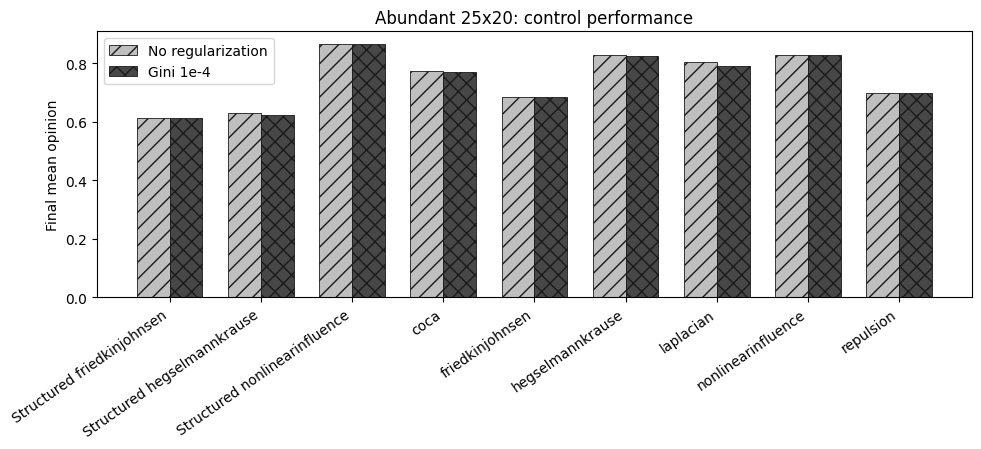

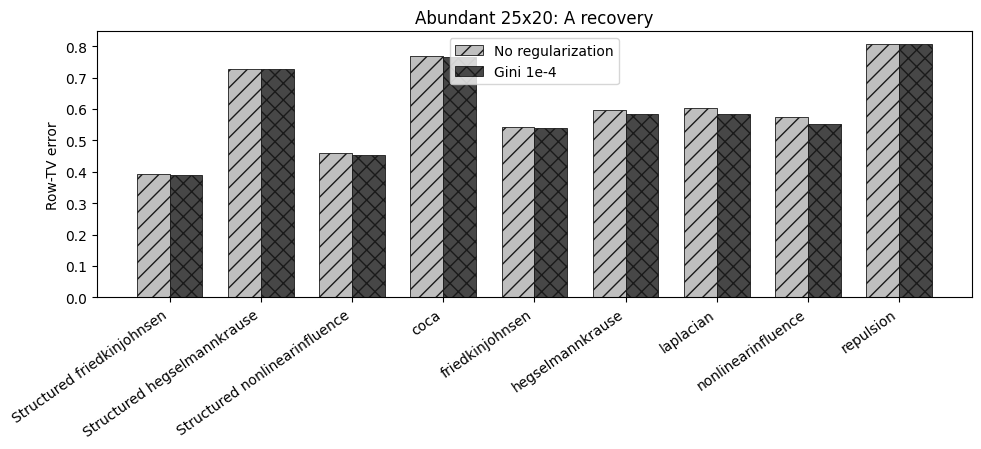

In [7]:

# Simple grayscale diagnostic plots.
plot = by_dyn.copy()
plot["label"] = np.where(
    plot["scenario_class"].eq("structured_mechanism"),
    "Structured " + plot["dynamics"],
    plot["dynamics"],
)

x = np.arange(len(plot))
width = 0.36
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(x - width/2, plot["none_control"], width, label="No regularization",
       color=".75", edgecolor=".1", linewidth=.6, hatch="//")
ax.bar(x + width/2, plot["gini_control"], width, label="Gini 1e-4",
       color=".28", edgecolor=".1", linewidth=.6, hatch="xx")
ax.set_xticks(x)
ax.set_xticklabels(plot["label"], rotation=35, ha="right")
ax.set_ylabel("Final mean opinion")
ax.set_title("Abundant 25x20: control performance")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "control_none_vs_gini.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(x - width/2, plot["none_rowTV"], width, label="No regularization",
       color=".75", edgecolor=".1", linewidth=.6, hatch="//")
ax.bar(x + width/2, plot["gini_rowTV"], width, label="Gini 1e-4",
       color=".28", edgecolor=".1", linewidth=.6, hatch="xx")
ax.set_xticks(x)
ax.set_xticklabels(plot["label"], rotation=35, ha="right")
ax.set_ylabel("Row-TV error")
ax.set_title("Abundant 25x20: A recovery")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "rowTV_none_vs_gini.png", dpi=300, bbox_inches="tight")
plt.show()


In [8]:

# Compact decision table. Positive control delta is good; negative row-TV is good.
decision = by_dyn[
    [
        "scenario_class", "dynamics", "delta_control",
        "delta_rowTV", "delta_edge_AP", "delta_pred_ratio"
    ]
].copy()
decision["control_improved"] = decision["delta_control"] > 0
decision["A_weight_recovery_improved"] = decision["delta_rowTV"] < 0
decision["support_AP_improved"] = decision["delta_edge_AP"] > 0
decision.to_csv(OUT / "decision_table.csv", index=False)
display(decision.round(6))

print("Analysis outputs:", OUT)


,scenario_class,dynamics,delta_control,delta_rowTV,delta_edge_AP,delta_pred_ratio,control_improved,A_weight_recovery_improved,support_AP_improved
0,structured_mechanism,friedkinjohnsen,0.000000,-0.002414,-0.002674,-0.002744,False,True,False
1,structured_mechanism,hegselmannkrause,-0.008819,-0.000598,-0.015053,-0.002519,False,True,False
2,structured_mechanism,nonlinearinfluence,0.000005,-0.005396,-0.038314,-0.005936,True,True,False
3,unstructured_random,coca,-0.002784,-0.003680,-0.077507,-0.002786,False,True,False
4,unstructured_random,friedkinjohnsen,0.000100,-0.002126,-0.001708,-0.001231,True,True,False
5,unstructured_random,hegselmannkrause,-0.003180,-0.012606,-0.037313,-0.007025,False,True,False
6,unstructured_random,laplacian,-0.012290,-0.020862,-0.150317,-0.005592,False,True,False
7,unstructured_random,nonlinearinfluence,-0.001888,-0.021969,-0.027315,-0.013981,False,True,False
8,unstructured_random,repulsion,-0.002853,0.000313,-0.000105,-0.001075,False,False,False


Analysis outputs: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\analysis_2026_10_02_abundant_25x20_none_vs_gini
